# 02 · Data Understanding — Cover Shadow Value (CSV)

Fase 2 do CRISP-DM (capítulo 5 do TFM). Dados: **SkillCorner Open Data** (licença MIT), jogo
1925299, Brisbane Roar – Perth Glory (21/12/2024), e a amostra de body pose de 12,3 s.

**O que queremos saber nesta fase:** o que os dados têm e o que não têm. Em concreto:
1. Que ficheiros há e o que descrevem (campo, equipas, jogadores).
2. Quantos jogadores têm pose em cada frame, e quantas articulações faltam.
3. Se o vetor de orientação do corpo (ombros) aponta mesmo para a frente, visto no campo.

Este notebook **explora**: descreve e desenha. Não tira conclusões sobre equipas ou jogadores.

## 1. Preparação

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mplsoccer import Pitch

from footy.ingest.skillcorner import (
    AMOSTRA_POSE,
    PASTA,
    dimensoes_campo,
    frames,
    jogadores_por_frame,
    ler_match,
)
from footy.viz.theme import apply_theme, load_brand

brand = load_brand()
apply_theme(brand)
FONTE = "SkillCorner Open Data (MIT)"
FPS_POSE = 25  # a pose tem 25 fotogramas por segundo (o tracking aberto tem 10)

## 2. O jogo: `match.json`

O campo **não é fixo**: vem no `match.json` (`pitch_length` × `pitch_width`, em metros), e as
coordenadas têm origem no centro do campo. `home_team_side` diz para que lado ataca cada equipa
em cada parte, por isso o sentido de ataque troca ao intervalo.

In [2]:
match = ler_match()
comprimento, largura = dimensoes_campo(match)
casa, fora = match["home_team"], match["away_team"]

print(f"{casa['name']} – {fora['name']}  ({match['home_team_score']}–{match['away_team_score']})")
print(f"Campo: {comprimento} × {largura} m")
print("Lado de ataque da equipa da casa, por parte:", match["home_team_side"])
for parte in match["match_periods"]:
    print(f"  parte {parte['period']}: frames {parte['start_frame']}–{parte['end_frame']} "
          f"({parte['duration_minutes']} min)")

Brisbane Roar FC – Perth Glory Football Club  (0–1)
Campo: 105 × 68 m
Lado de ataque da equipa da casa, por parte: ['right_to_left', 'left_to_right']
  parte 1: frames 10–30240 (50.38 min)
  parte 2: frames 30250–61300 (51.75 min)


In [3]:
jogadores = pd.DataFrame([
    {
        "jogador": p["id"],
        "equipa_id": p["team_id"],
        "camisola": p["number"],
        "posicao": p["player_role"]["acronym"],
        "grupo": p["player_role"]["position_group"],
        "nome": p["short_name"],
    }
    for p in match["players"]
])
print(f"{len(jogadores)} jogadores no plantel do jogo")
jogadores.groupby(["equipa_id", "grupo"]).size().unstack(fill_value=0)

36 jogadores no plantel do jogo


grupo,Center Forward,Central Defender,Full Back,Midfield,Other,Wide Attacker
equipa_id,,,,,,
871,4,2,2,2,3,5
1802,1,3,3,4,3,4


## 3. A amostra de body pose

Cada linha do ficheiro é um frame, com a posição de cada jogador (`x`, `y`), se foi detetado
(`is_detected`) e as 29 articulações (`joints`), ou `null` quando a pose não foi resolvida.
O `player_id` da pose corresponde ao campo `id` dos jogadores do `match.json`.

In [4]:
amostra = PASTA / "bodypose" / AMOSTRA_POSE
todos = list(frames(amostra))  # são só 12 s; o jogo inteiro processa-se frame a frame

tabela = jogadores_por_frame(iter(todos)).merge(jogadores, on="jogador", how="left")
print("Jogadores da pose sem correspondência no match.json:", tabela["nome"].isna().sum())

primeiro, ultimo = tabela["frame"].min(), tabela["frame"].max()
print(f"{tabela['frame'].nunique()} frames ({primeiro}–{ultimo}), "
      f"{(ultimo - primeiro) / FPS_POSE:.1f} s, parte {tabela['periodo'].unique().tolist()}")

Jogadores da pose sem correspondência no match.json: 0
309 frames (124487–124795), 12.3 s, parte [2]


## 4. Qualidade: quem tem pose?

Duas perguntas diferentes: o jogador foi **detetado** (tem posição medida) e tem **pose**
(articulações)? Contam-se por jogador-frame. Isto é só a amostra de 12 s: o README do dataset dá
os números do jogo todo.

In [5]:
pd.Series({
    "entradas jogador-frame": len(tabela),
    "detetados": tabela["detetado"].mean(),
    "com pose": tabela["tem_pose"].mean(),
    "com pose mas não detetados": (tabela["tem_pose"] & ~tabela["detetado"]).sum(),
    "detetados sem pose": (tabela["detetado"] & ~tabela["tem_pose"]).sum(),
})

entradas jogador-frame        9888.000000
detetados                        0.502933
com pose                         0.500910
com pose mas não detetados       0.000000
detetados sem pose              20.000000
dtype: float64

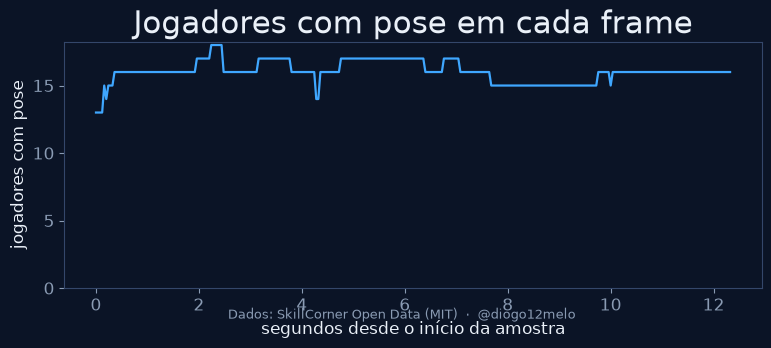

In [6]:
com_pose_por_frame = tabela.groupby("frame")["tem_pose"].sum()
segundos = (com_pose_por_frame.index - primeiro) / FPS_POSE

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(segundos, com_pose_por_frame.values, color=brand.colors["secondary"], lw=1.6)
ax.set_xlabel("segundos desde o início da amostra")
ax.set_ylabel("jogadores com pose")
ax.set_title("Jogadores com pose em cada frame")
ax.set_ylim(0)
fig.text(0.5, 0.005, brand.credit(FONTE), ha="center", va="bottom", color=brand.colors["text_muted"], fontsize=9)
plt.show()

In [7]:
por_jogador = (
    tabela.groupby(["equipa_id", "camisola", "posicao"])["tem_pose"].mean().mul(100).round(0)
    .rename("% de frames com pose").reset_index()
    .sort_values("% de frames com pose", ascending=False)
)
por_jogador

,equipa_id,camisola,posicao,% de frames com pose
3,871,12,RM,100.0
7,871,17,RW,100.0
12,871,26,LW,100.0
8,871,19,RB,100.0
29,1802,26,LDM,100.0
25,1802,18,RW,100.0
28,1802,23,LW,100.0
1,871,7,LM,99.0
26,1802,19,RB,99.0
30,1802,30,AM,99.0


### Articulações em falta

Quando há pose, estão as 29 articulações? E quão precisa é cada uma? `p90_mae_cm` é o erro
(percentil 90, em cm) que a SkillCorner estima para cada articulação.

In [8]:
presentes, erros = {}, {}
frames_com_pose = 0
for frame in todos:
    for jogador in frame["player_data"]:
        if not jogador.get("joints"):
            continue
        frames_com_pose += 1
        for nome, valor in jogador["joints"].items():
            presentes[nome] = presentes.get(nome, 0) + 1
            erros.setdefault(nome, []).append(valor["p90_mae_cm"])

articulacoes = pd.DataFrame({
    "% das poses com a articulação": {k: 100 * v / frames_com_pose for k, v in presentes.items()},
    "p90_mae_cm (mediana)": {k: float(np.median(v)) for k, v in erros.items()},
}).round(1).sort_values("p90_mae_cm (mediana)")
print(f"{frames_com_pose} poses; {len(articulacoes)} articulações diferentes")
articulacoes

4953 poses; 29 articulações diferentes


,% das poses com a articulação,p90_mae_cm (mediana)
neck,100.0,5.0
rShoulder,100.0,5.6
lShoulder,100.0,5.7
rEar,100.0,6.7
rEye,100.0,6.8
lEar,100.0,6.8
lEye,100.0,6.9
nose,100.0,7.3
lHip,100.0,7.3
rHip,100.0,7.8


## 5. Os bonecos no campo

Desenho **visto de cima** (só `x` e `y`): o `z` da pose não é altura acima do relvado, é relativo
ao centro do jogador (aviso do README). Escolhe-se o frame com mais jogadores com pose; `frame_exemplo` pode ser alterado
para ver outro.

Cores: equipa sem a bola em azul, equipa com a bola em cinzento. A bola em branco.

In [9]:
LIGACOES = [  # pares de articulações que formam o esqueleto
    ("nose", "neck"), ("neck", "lShoulder"), ("neck", "rShoulder"),
    ("lShoulder", "lElbow"), ("lElbow", "lWrist"), ("rShoulder", "rElbow"), ("rElbow", "rWrist"),
    ("neck", "midHip"), ("midHip", "lHip"), ("midHip", "rHip"),
    ("lHip", "lKnee"), ("lKnee", "lAnkle"), ("rHip", "rKnee"), ("rKnee", "rAnkle"),
]
por_numero = {f["frame"]: f for f in todos}
frame_exemplo = int(com_pose_por_frame.idxmax())


def equipa_sem_bola(frame):
    """Id da equipa que defende (a que não tem a posse), ou None se ninguém tem a bola."""
    grupo = frame["possession"]["group"]
    if grupo == "home team":
        return fora["id"]
    if grupo == "away team":
        return casa["id"]
    return None


def desenhar_esqueleto(ax, joints, cor):
    for a, b in LIGACOES:
        if a in joints and b in joints:
            (xa, ya, _), (xb, yb, _) = joints[a]["xyz"], joints[b]["xyz"]
            ax.plot([xa, xb], [ya, yb], color=cor, lw=1.6, solid_capstyle="round", zorder=3)
    # De cima o corpo quase some; os ombros (linha grossa) e o nariz (ponto) mostram para onde olha.
    if "lShoulder" in joints and "rShoulder" in joints:
        (xa, ya, _), (xb, yb, _) = joints["lShoulder"]["xyz"], joints["rShoulder"]["xyz"]
        ax.plot([xa, xb], [ya, yb], color=cor, lw=4, solid_capstyle="round", zorder=4)
    if "nose" in joints:
        ax.scatter([joints["nose"]["xyz"][0]], [joints["nose"]["xyz"][1]], s=22, color=cor, zorder=4)


def criar_campo():
    return Pitch(pitch_type="skillcorner", pitch_length=comprimento, pitch_width=largura,
                 pitch_color=brand.colors["pitch"], line_color=brand.colors["lines"], linewidth=1.2)


def novo_campo():
    fig, ax = criar_campo().draw(figsize=(11, 7.4))
    return fig, ax

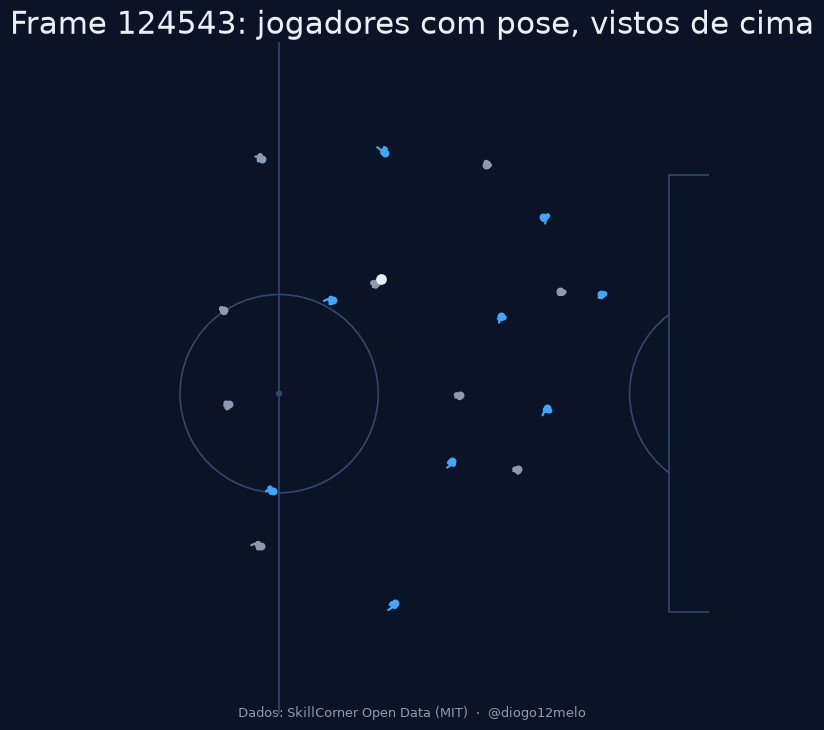

In [10]:
equipa_de = dict(zip(jogadores["jogador"], jogadores["equipa_id"]))


def desenhar_frame(numero, orientacao=None, margem=10):
    frame = por_numero[numero]
    fig, ax = novo_campo()
    defesa = equipa_sem_bola(frame)
    xs, ys = [], []
    for jogador in frame["player_data"]:
        if not jogador.get("joints"):
            continue
        cor = brand.colors["secondary"] if equipa_de[jogador["player_id"]] == defesa else brand.colors["text_muted"]
        desenhar_esqueleto(ax, jogador["joints"], cor)
        xs.append(jogador["x"]); ys.append(jogador["y"])
        if orientacao is not None:
            frente = orientacao(jogador["joints"])
            if frente is not None:
                ax.annotate("", xy=(jogador["x"] + 2.5 * frente[0], jogador["y"] + 2.5 * frente[1]),
                            xytext=(jogador["x"], jogador["y"]), zorder=5,
                            arrowprops={"arrowstyle": "-|>", "color": brand.colors["primary"], "lw": 2.2})
    bola = frame["ball_data"]
    ax.scatter([bola["x"]], [bola["y"]], s=45, color=brand.colors["text"], zorder=6)
    ax.set_xlim(min(xs) - margem, max(xs) + margem)  # aproxima aos jogadores com pose
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    fig.text(0.5, 0.02, brand.credit(FONTE), ha="center", color=brand.colors["text_muted"], fontsize=9)
    return fig, ax


fig, ax = desenhar_frame(frame_exemplo)
ax.set_title(f"Frame {frame_exemplo}: jogadores com pose, vistos de cima")
plt.show()

## 6. Orientação do corpo

Regra do projeto: **frente = perpendicular ao vetor ombro esquerdo → ombro direito, rodado 90°
no sentido anti-horário**, só em `x` e `y`. A confirmação é com o nariz: se o nariz estiver à
frente do pescoço, o vetor aponta para onde o jogador olha.

Setas laranja = orientação do corpo calculada.

In [11]:
def frente_do_corpo(joints):
    """Vetor unitário (x, y) para onde o peito aponta, ou None se faltarem os ombros."""
    if "lShoulder" not in joints or "rShoulder" not in joints:
        return None
    esquerdo = np.array(joints["lShoulder"]["xyz"][:2])
    direito = np.array(joints["rShoulder"]["xyz"][:2])
    ombros = direito - esquerdo
    frente = np.array([-ombros[1], ombros[0]])  # rodar 90° no sentido anti-horário
    norma = np.linalg.norm(frente)
    return frente / norma if norma > 0 else None


def nariz_a_frente(joints):
    """True se o nariz está à frente do pescoço segundo a orientação calculada; None se não dá para ver."""
    frente = frente_do_corpo(joints)
    if frente is None or "nose" not in joints or "neck" not in joints:
        return None
    nariz = np.array(joints["nose"]["xyz"][:2]) - np.array(joints["neck"]["xyz"][:2])
    return bool(nariz @ frente > 0)


testes = [nariz_a_frente(j["joints"]) for f in todos for j in f["player_data"] if j.get("joints")]
vistos = [t for t in testes if t is not None]
print(f"Nariz à frente do pescoço: {sum(vistos)} de {len(vistos)} poses "
      f"({100 * sum(vistos) / len(vistos):.1f}%); sem ombros ou nariz: {len(testes) - len(vistos)}")

Nariz à frente do pescoço: 4947 de 4953 poses (99.9%); sem ombros ou nariz: 0


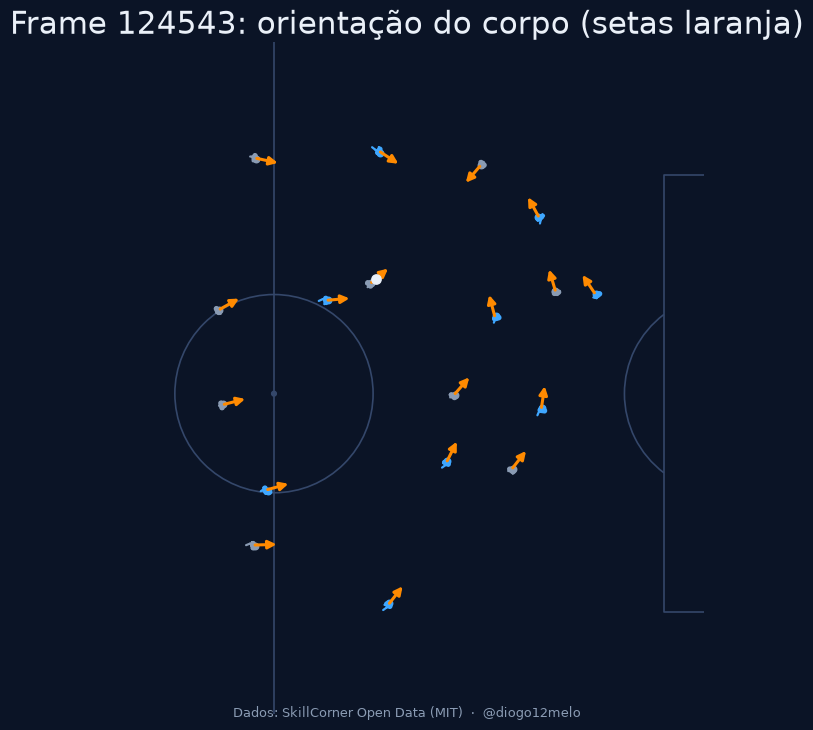

In [12]:
fig, ax = desenhar_frame(frame_exemplo, orientacao=frente_do_corpo)
ax.set_title(f"Frame {frame_exemplo}: orientação do corpo (setas laranja)")
plt.show()

## 7. A amostra em movimento, e a orientação contra a corrida

Duas coisas, ambas descritivas:
- **7.1 Animação** dos 12 s: esqueletos vistos de cima, seta laranja da orientação do peito,
  bola, e um rasto de cerca de 1 s com o caminho de cada jogador.
- **7.2 Corrida contra peito:** quando um jogador corre depressa, para onde corre em relação
  para onde o peito aponta? Defender de lado ou de costas é normal, por isso desacordo não é
  forçosamente erro: os exemplos permitem ver cada caso.

O mplsoccer não traz uma animação de tracking pronta; segue-se o padrão do exemplo oficial
(`Pitch` + `matplotlib.animation.FuncAnimation`, o mesmo dos vídeos dos penáltis e dos livres), com
os rastos feitos com as comet lines do mplsoccer (`pitch.lines(..., comet=True, transparent=True)`),
redesenhadas em cada frame com as posições do último segundo. Os rastos usam a cor de cada equipa;
o laranja fica só para as setas de orientação.

### 7.1 Animação

In [13]:
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.collections import LineCollection

from footy.paths import output_dir
from footy.video.compose import save_animation

FRAMES_RASTO = FPS_POSE  # 1 s de rasto
TROCOS_RASTO = 5         # o rasto é desenhado em 5 troços, cada um mais visível que o anterior
posicao = {(r.frame, r.jogador): (r.x, r.y) for r in tabela.itertuples()}  # para os rastos


def jogadores_com_pose(frame):
    return [j for j in frame["player_data"] if j.get("joints")]


def cor_do_jogador(jogador, defesa):
    azul_ou_cinza = "secondary" if equipa_de[jogador["player_id"]] == defesa else "text_muted"
    return brand.colors[azul_ou_cinza]


def pontos_do_rasto(jogador_id, numero):
    """Posições (x, y) do jogador desde 1 s atrás até agora, em TROCOS_RASTO + 1 instantes."""
    instantes = np.linspace(numero - FRAMES_RASTO, numero, TROCOS_RASTO + 1).round().astype(int)
    return np.array([posicao[(max(g, primeiro), jogador_id)] for g in instantes])


def desenhar_rastos(campo, ax, jogadores_da_equipa, cor, numero):
    """Rasto de 1 s de cada jogador, com as comet lines do mplsoccer. Cada troço é um comet que ganha
    opacidade até à posição atual, e a opacidade continua de um troço para o seguinte. A cor é a da
    equipa: o laranja não leva transparência, fica só para as setas."""
    if not jogadores_da_equipa:
        return []
    trajetos = np.array([pontos_do_rasto(j["player_id"], numero) for j in jogadores_da_equipa])
    artistas = []
    for k in range(TROCOS_RASTO):
        troco = campo.lines(trajetos[:, k, 0], trajetos[:, k, 1], trajetos[:, k + 1, 0], trajetos[:, k + 1, 1],
                            ax=ax, color=cor, lw=2.5, comet=True, transparent=True, n_segments=8,
                            alpha_start=max(k / TROCOS_RASTO, 0.02), alpha_end=(k + 1) / TROCOS_RASTO, zorder=2)
        artistas += list(troco) if isinstance(troco, list) else [troco]
    return artistas


def segmentos(joints, pares):
    return [[joints[a]["xyz"][:2], joints[b]["xyz"][:2]]
            for a, b in pares if a in joints and b in joints]


def desenhar_jogador(ax, jogador, cor):
    joints = jogador["joints"]
    artistas = []
    for pares, espessura in [(LIGACOES, 1.6), ([("lShoulder", "rShoulder")], 4)]:
        linhas = LineCollection(segmentos(joints, pares), colors=cor, linewidths=espessura,
                                capstyle="round", zorder=3)
        artistas.append(ax.add_collection(linhas))
    frente = frente_do_corpo(joints)
    if frente is not None:
        artistas.append(ax.annotate(
            "", xy=(jogador["x"] + 2.5 * frente[0], jogador["y"] + 2.5 * frente[1]),
            xytext=(jogador["x"], jogador["y"]), zorder=5,
            arrowprops={"arrowstyle": "-|>", "color": brand.colors["primary"], "lw": 2.2}))
    return artistas


def desenhar_instante(campo, ax, numero):
    """Tudo o que há num frame; devolve os artistas para serem apagados no frame seguinte."""
    frame = por_numero[numero]
    defesa = equipa_sem_bola(frame)
    artistas = []
    por_cor = {}
    for jogador in jogadores_com_pose(frame):
        cor = cor_do_jogador(jogador, defesa)
        por_cor.setdefault(cor, []).append(jogador)
        artistas += desenhar_jogador(ax, jogador, cor)
    for cor, jogadores_da_equipa in por_cor.items():
        artistas += desenhar_rastos(campo, ax, jogadores_da_equipa, cor, numero)
    bola = frame["ball_data"]
    artistas.append(ax.scatter([bola["x"]], [bola["y"]], s=45, color=brand.colors["text"], zorder=6))
    return artistas


def criar_animacao(numeros):
    campo = criar_campo()
    fig, ax = campo.draw(figsize=(11, 7.4))
    fig.set_dpi(100)
    com_pose = tabela[tabela["tem_pose"]]  # enquadramento fixo, para a câmara não saltar
    ax.set_xlim(com_pose["x"].min() - 8, com_pose["x"].max() + 8)
    ax.set_ylim(com_pose["y"].min() - 8, com_pose["y"].max() + 8)
    ax.set_title("Amostra de 12 s: esqueleto, orientação do peito e rasto de 1 s")
    fig.text(0.5, 0.02, brand.credit(FONTE), ha="center", color=brand.colors["text_muted"], fontsize=9)
    relogio = ax.text(0.02, 0.97, "", transform=ax.transAxes, va="top", color=brand.colors["text"])
    atuais = []

    def atualizar(i):
        for artista in atuais:
            artista.remove()
        atuais[:] = desenhar_instante(campo, ax, numeros[i])
        relogio.set_text(f"{(numeros[i] - primeiro) / FPS_POSE:4.1f} s")
        return atuais

    animacao = FuncAnimation(fig, atualizar, frames=len(numeros), interval=1000 / FPS_POSE)
    plt.close(fig)  # não mostrar a figura estática por baixo
    return animacao

MP4: outputs\cover_shadow\amostra_pose_12s.mp4
GIF: outputs\cover_shadow\amostra_pose_12s.gif


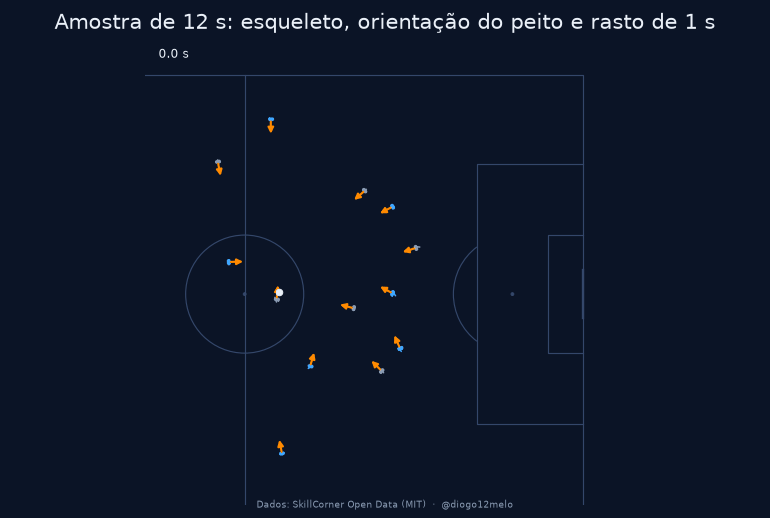

In [14]:
pasta = output_dir("cover_shadow")
numeros = sorted(por_numero)

# MP4 em tempo real (25 fps); GIF mais leve (metade dos frames, resolução mais baixa).
mp4 = save_animation(criar_animacao(numeros), pasta / "amostra_pose_12s.mp4", fps=FPS_POSE)
gif = pasta / "amostra_pose_12s.gif"
criar_animacao(numeros[::2]).save(gif, writer=PillowWriter(fps=FPS_POSE / 2), dpi=70)

print(f"MP4: {mp4}\nGIF: {gif}")
display(Image(filename=gif))

### 7.2 Corrida contra peito

Para cada jogador e frame: posição suavizada (média móvel de ~0,4 s), velocidade a partir da
variação da posição, e a direção da corrida. Só entram os frames com pose e a **mais de 4 m/s**.
Depois mede-se o ângulo entre a direção da corrida e a seta do peito: 0° = corre para onde o
peito aponta, 90° = corre de lado, 180° = corre de costas.

In [15]:
JANELA = round(0.4 * FPS_POSE)  # ~0,4 s em frames
VELOCIDADE_MINIMA = 4.0         # m/s


def velocidade_de_um_jogador(t):
    """Velocidade e direção da corrida de um jogador, pelas posições suavizadas."""
    t = t.sort_values("frame").copy()
    assert t["frame"].diff().dropna().eq(1).all(), "frames em falta: a velocidade seria falsa"
    for eixo in "xy":
        suave = t[eixo].rolling(JANELA, center=True, min_periods=JANELA).mean()
        t[f"v{eixo}"] = np.gradient(suave.to_numpy()) * FPS_POSE  # m por frame -> m/s
    t["velocidade"] = np.hypot(t["vx"], t["vy"])
    return t


velocidades = pd.concat(velocidade_de_um_jogador(t) for _, t in tabela.groupby("jogador"))
velocidades[["velocidade"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
velocidade,9536.0,1.77,1.73,0.0,0.0,1.31,3.12,7.31


In [16]:
def orientacoes_do_peito(frames_):
    linhas = []
    for frame in frames_:
        for jogador in jogadores_com_pose(frame):
            frente = frente_do_corpo(jogador["joints"])
            if frente is not None:
                linhas.append({"frame": frame["frame"], "jogador": jogador["player_id"],
                               "fx": frente[0], "fy": frente[1]})
    return pd.DataFrame(linhas)


def angulo_entre(ax_, ay, bx, by):
    """Ângulo em graus (0–180) entre dois vetores."""
    cos = (ax_ * bx + ay * by) / (np.hypot(ax_, ay) * np.hypot(bx, by))
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))


comparacao = velocidades.merge(orientacoes_do_peito(todos), on=["frame", "jogador"])
comparacao["angulo"] = angulo_entre(comparacao["vx"], comparacao["vy"],
                                    comparacao["fx"], comparacao["fy"])
rapidos = comparacao[comparacao["velocidade"] > VELOCIDADE_MINIMA].copy()
defesa_por_frame = {n: equipa_sem_bola(f) for n, f in por_numero.items()}
rapidos["defende"] = [equipa_de[j] == defesa_por_frame[n] for n, j in zip(rapidos["frame"], rapidos["jogador"])]

print(f"Frames com pose e velocidade medida: {len(comparacao)}")
print(f"A mais de {VELOCIDADE_MINIMA} m/s: {len(rapidos)} jogador-frames de {rapidos['jogador'].nunique()} jogadores")
pd.Series({
    "ângulo < 45°": (rapidos["angulo"] < 45).mean() * 100,
    "ângulo < 90°": (rapidos["angulo"] < 90).mean() * 100,
    "ângulo > 135° (corre de costas)": (rapidos["angulo"] > 135).mean() * 100,
}).round(1).rename("% dos jogador-frames rápidos")

Frames com pose e velocidade medida: 4953
A mais de 4.0 m/s: 1079 jogador-frames de 13 jogadores


ângulo < 45°                       93.1
ângulo < 90°                       98.1
ângulo > 135° (corre de costas)     1.1
Name: % dos jogador-frames rápidos, dtype: float64

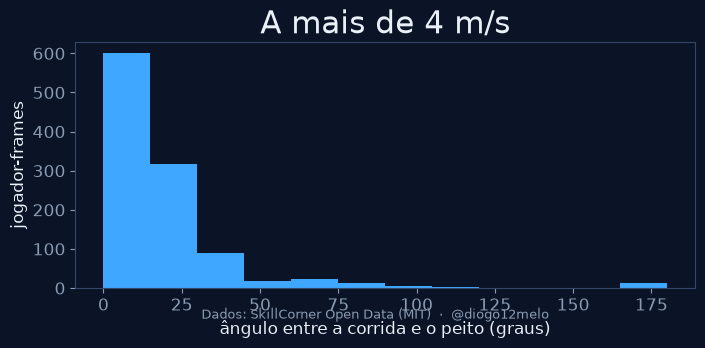

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(rapidos["angulo"], bins=range(0, 181, 15), color=brand.colors["secondary"])
ax.set_xlabel("ângulo entre a corrida e o peito (graus)")
ax.set_ylabel("jogador-frames")
ax.set_title(f"A mais de {VELOCIDADE_MINIMA:g} m/s")
fig.text(0.5, 0.005, brand.credit(FONTE), ha="center", va="bottom", color=brand.colors["text_muted"], fontsize=9)
plt.show()

**Casos de maior desacordo.** Para cada um dos 2 jogadores com o maior ângulo (um frame por
jogador): esqueleto, seta laranja do peito, seta branca da corrida e o caminho de ±0,5 s (linha
grossa cinzenta) à volta desse frame. Permite distinguir corrida de lado ou de costas de um erro
no cálculo da orientação.

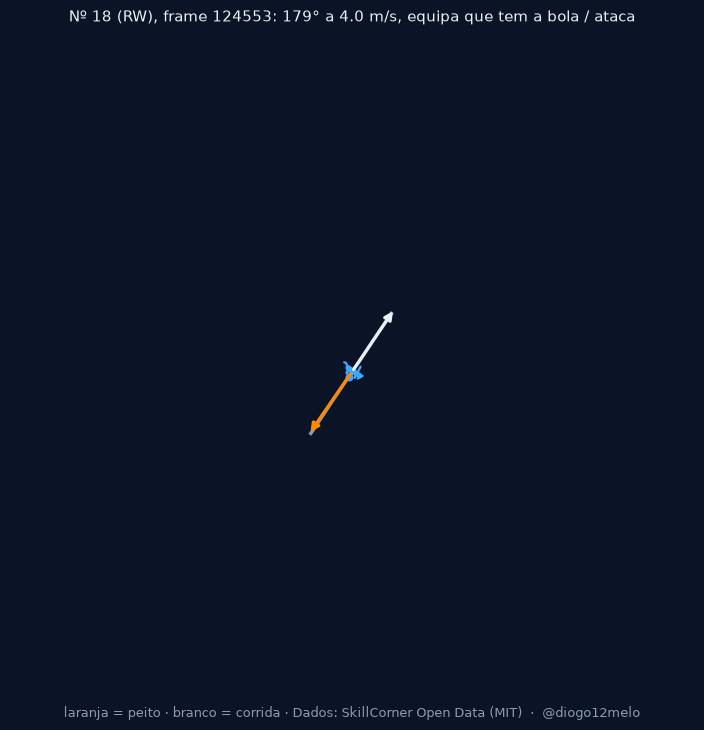

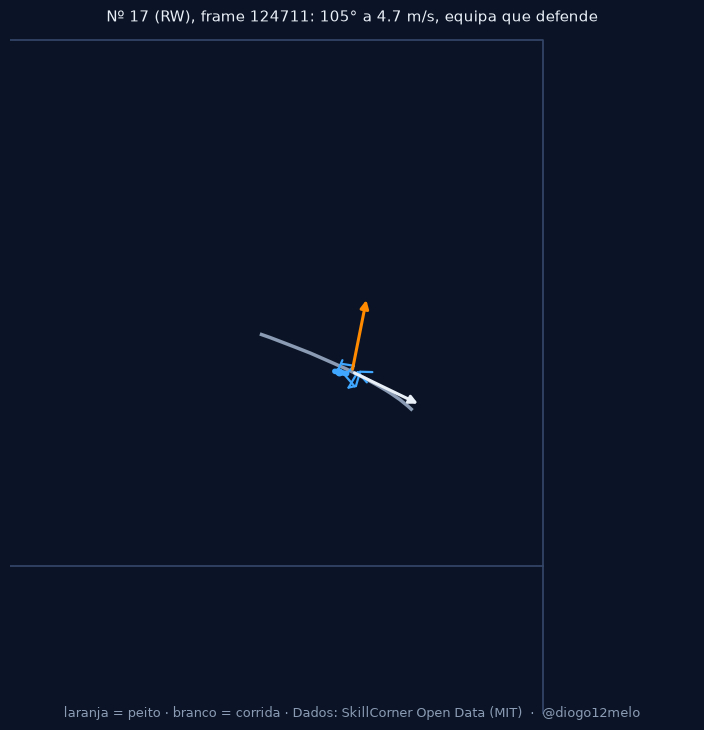

In [18]:
def desenhar_exemplo(linha, margem=9):
    numero, pid = int(linha.frame), int(linha.jogador)
    jogador = next(j for j in por_numero[numero]["player_data"] if j["player_id"] == pid)
    ficha = jogadores.set_index("jogador").loc[pid]
    fig, ax = novo_campo()
    desenhar_esqueleto(ax, jogador["joints"], brand.colors["secondary"])
    caminho = np.array([posicao[(g, pid)] for g in range(numero - 12, numero + 13) if (g, pid) in posicao])
    ax.plot(caminho[:, 0], caminho[:, 1], color=brand.colors["text_muted"], lw=2.5, zorder=2)
    for dx, dy, cor in [(linha.fx, linha.fy, brand.colors["primary"]),
                        (linha.vx / linha.velocidade, linha.vy / linha.velocidade, brand.colors["text"])]:
        ax.annotate("", xy=(jogador["x"] + 2 * dx, jogador["y"] + 2 * dy), xytext=(jogador["x"], jogador["y"]),
                    zorder=5, arrowprops={"arrowstyle": "-|>", "color": cor, "lw": 2.2})
    ax.set_xlim(jogador["x"] - margem, jogador["x"] + margem)
    ax.set_ylim(jogador["y"] - margem, jogador["y"] + margem)
    papel = "defende" if linha.defende else "tem a bola / ataca"
    ax.set_title(f"Nº {ficha['camisola']} ({ficha['posicao']}), frame {numero}: {linha.angulo:.0f}° "
                 f"a {linha.velocidade:.1f} m/s, equipa que {papel}", fontsize=11)
    fig.text(0.5, 0.02, "laranja = peito · branco = corrida · " + brand.credit(FONTE),
             ha="center", color=brand.colors["text_muted"], fontsize=9)
    plt.show()


maiores = rapidos.sort_values("angulo", ascending=False).drop_duplicates("jogador").head(2)
for linha in maiores.itertuples():
    desenhar_exemplo(linha)

### O que cada parte faz, em linguagem corrente

- **Animação.** Passa os 309 frames da amostra um a um, como um filme de 12 s visto de cima. Em
  cada frame desenha, para cada jogador com pose, o esqueleto (os ombros mais grossos e o
  nariz mostram para onde olha), a seta laranja do peito e um rasto (comet lines) com o caminho do
  último segundo. O enquadramento é fixo para a câmara não saltar. Guarda um MP4 em tempo real e um
  GIF mais leve em `outputs/cover_shadow/`.
- **Velocidade.** A posição de cada jogador tem pequenos tremores; por isso alisa-se com uma
  média de ~0,4 s e só depois se vê quanto a posição muda de frame para frame. Isso dá a
  velocidade (m/s) e a direção em que o jogador corre.
- **Comparação.** Para os frames em que o jogador corre a mais de 4 m/s, mede o ângulo entre
  essa direção e a seta do peito, e conta que parte fica abaixo de 45° e de 90°.
- **Exemplos.** Mostra os dois casos mais discordantes, cada um de um jogador diferente, com as
  duas setas e o caminho, para distinguir erro de cálculo de corrida de lado ou de costas.

Nada disto interpreta os números: são medições.

## 8. Síntese da fase

Os números abaixo são calculados nas secções anteriores (amostra de 12 s do jogo 1925299).


In [19]:
from IPython.display import Markdown

faixa_erro = articulacoes["p90_mae_cm (mediana)"]
Markdown(f'''
- **Dados:** {casa['name']} – {fora['name']}, campo de {comprimento:g} × {largura:g} m, coordenadas em
  metros com origem no centro; o sentido de ataque troca de uma parte para a outra.
- **Amostra:** {tabela['frame'].nunique()} frames ({(ultimo - primeiro) / FPS_POSE:.1f} s, 25 fps) da parte {tabela['periodo'].iloc[0]}.
- **Cobertura:** {tabela['detetado'].mean() * 100:.1f}% dos jogador-frames detetados e {tabela['tem_pose'].mean() * 100:.1f}% com pose;
  pose sem deteção: {(tabela['tem_pose'] & ~tabela['detetado']).sum()} jogador-frames.
- **Articulações:** {len(articulacoes)} articulações; cada uma presente em pelo menos
  {articulacoes.iloc[:, 0].min():.0f}% das poses; erro p90 mediano entre {faixa_erro.min():.1f} e {faixa_erro.max():.1f} cm.
- **Orientação do peito:** nariz à frente do pescoço em {sum(vistos)} de {len(vistos)} poses ({100 * sum(vistos) / len(vistos):.1f}%).
- **Corrida contra peito** (a mais de {VELOCIDADE_MINIMA:g} m/s, {len(rapidos)} jogador-frames de {rapidos['jogador'].nunique()} jogadores):
  ângulo abaixo de 45° em {(rapidos['angulo'] < 45).mean() * 100:.1f}%, abaixo de 90° em {(rapidos['angulo'] < 90).mean() * 100:.1f}%,
  acima de 135° em {(rapidos['angulo'] > 135).mean() * 100:.1f}%.
''')


- **Dados:** Brisbane Roar FC – Perth Glory Football Club, campo de 105 × 68 m, coordenadas em
  metros com origem no centro; o sentido de ataque troca de uma parte para a outra.
- **Amostra:** 309 frames (12.3 s, 25 fps) da parte 2.
- **Cobertura:** 50.3% dos jogador-frames detetados e 50.1% com pose;
  pose sem deteção: 0 jogador-frames.
- **Articulações:** 29 articulações; cada uma presente em pelo menos
  100% das poses; erro p90 mediano entre 5.0 e 16.5 cm.
- **Orientação do peito:** nariz à frente do pescoço em 4947 de 4953 poses (99.9%).
- **Corrida contra peito** (a mais de 4 m/s, 1079 jogador-frames de 13 jogadores):
  ângulo abaixo de 45° em 93.1%, abaixo de 90° em 98.1%,
  acima de 135° em 1.1%.


**Limitações dos dados, nesta amostra**
- A amostra tem 12 s de um jogo: os valores descrevem estes frames e não generalizam para o jogo.
- O `z` da pose é relativo ao centro do jogador, não é altura acima do relvado; a orientação usa
  apenas `x` e `y`.
- Tracking e pose são gerados em separado, o que pode causar pequenos desalinhamentos entre ambos
  (aviso do dataset).
- Em cada frame há jogadores sem pose (fora de câmara, tapados ou não detetados); a pose existe
  só para os detetados.

Na amostra de 12 segundos, 50% das combinações jogador–frame tinham pose; no jogo inteiro, segundo a SkillCorner, a cobertura ronda um terço. A pose só existe para jogadores detetados pela câmara e, quando existe, inclui sempre as 29 articulações. A orientação do peito foi calculada a partir dos ombros e o nariz confirma-a em 99,9% dos casos. Limitações: apenas 2 jogos com pose, sem vídeo, e pose e tracking produzidos em separado.